## [6] Evaluation and Comparison

### 6.1 Classification (Decision Tree)

In this part we apply the Decision Tree classifier using **two attribute selection measures** (Information Gain / Entropy and Gini index) on **three different partitions** of the data (90/10, 80/20, 70/30). For each measure and each partition we report the accuracy and the confusion matrix, then compare the results.

`random_state=42` is used in every split and every model, so the comparison between Gini and Entropy is done on exactly the same training and testing samples.

**Step 1: Load the preprocessed dataset and prepare the inputs (X) and the target (y).** The identifier and text columns `PassengerId`, `Name` and `Ticket` are dropped because they are not useful for training.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

url = 'https://raw.githubusercontent.com/Razan445/IT326-Project/refs/heads/main/Dataset/Preprocessed_dataset.csv'
df_preprocessed = pd.read_csv(url)

df_model = df_preprocessed.drop(columns=['PassengerId', 'Name', 'Ticket'])

X = df_model.drop(columns=['Survived'])
y = df_model['Survived']

print(X.dtypes)
print(X.shape)

Pclass          int64
Sex             int64
Age           float64
SibSp         float64
Parch         float64
Fare          float64
Embarked_C       bool
Embarked_Q       bool
Embarked_S       bool
dtype: object
(891, 9)


**Step 2: A helper function** that trains the Decision Tree with both measures on one partition, prints the accuracy, and draws the confusion matrices. The accuracies are stored in `results` to build the summary tables later.

In [ ]:
results = {}   # (criterion, partition) -> accuracy

def evaluate_partition(test_size, label):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, crit in zip(axes, ["gini", "entropy"]):
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=42)
        model = DecisionTreeClassifier(criterion=crit, random_state=42)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        results[(crit, label)] = acc

        print(f"{crit} | {label} | Accuracy = {acc:.4f}")
        print(confusion_matrix(y_test, y_pred), "\n")

        ConfusionMatrixDisplay(
            confusion_matrix(y_test, y_pred),
            display_labels=["Not Survived", "Survived"]
        ).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{crit} | {label} | acc = {acc:.3f}")
    plt.tight_layout()
    plt.show()

**Partition 1: 90% training / 10% testing**

gini | 90/10 | Accuracy = 0.8000
[[43 11]
 [ 7 29]] 

entropy | 90/10 | Accuracy = 0.8000
[[43 11]
 [ 7 29]] 



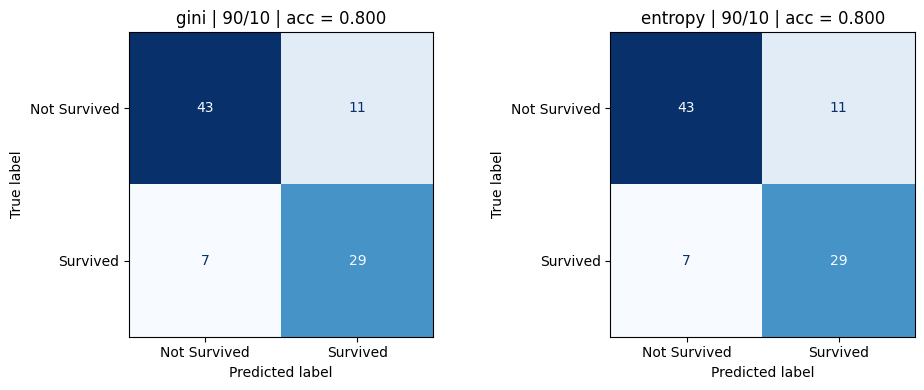

In [ ]:
evaluate_partition(0.10, "90/10")

**Partition 2: 80% training / 20% testing**

gini | 80/20 | Accuracy = 0.7542
[[83 22]
 [22 52]] 

entropy | 80/20 | Accuracy = 0.7709
[[84 21]
 [20 54]] 



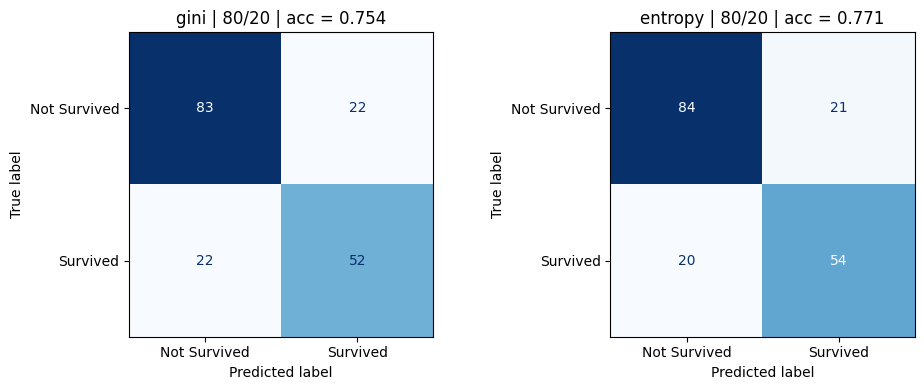

In [ ]:
evaluate_partition(0.20, "80/20")

**Partition 3: 70% training / 30% testing**

gini | 70/30 | Accuracy = 0.7463
[[127  30]
 [ 38  73]] 

entropy | 70/30 | Accuracy = 0.7687
[[132  25]
 [ 37  74]] 



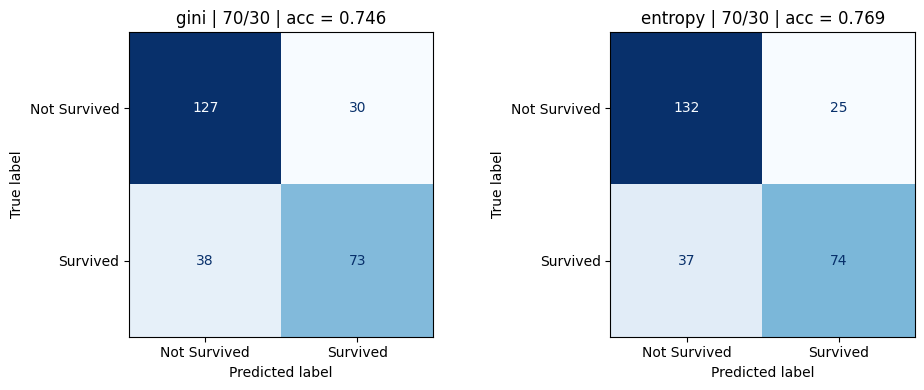

In [ ]:
evaluate_partition(0.30, "70/30")

**Step 3: Summary tables.** One table for each attribute selection measure.

In [ ]:
labels = ["90/10", "80/20", "70/30"]
columns = ["90% training / 10% testing", "80% training / 20% testing", "70% training / 30% testing"]

for crit, title in [("entropy", "Information Gain (Entropy)"), ("gini", "Gini index")]:
    table = pd.DataFrame([[round(results[(crit, l)], 4) for l in labels]],
                         index=["Accuracy"], columns=columns)
    print(f"Attribute selection measure: {title}")
    display(table)

Attribute selection measure: Information Gain (Entropy)


,90% training / 10% testing,80% training / 20% testing,70% training / 30% testing
Accuracy,0.8,0.7709,0.7687


Attribute selection measure: Gini index


,90% training / 10% testing,80% training / 20% testing,70% training / 30% testing
Accuracy,0.8,0.7542,0.7463


**Step 4: Best measure for each partition and overall.**

In [ ]:
for l in labels:
    g, e = results[("gini", l)], results[("entropy", l)]
    winner = "Tie" if abs(g - e) < 1e-12 else ("Entropy" if e > g else "Gini")
    print(f"{l}: Gini = {g:.4f} | Entropy = {e:.4f} -> best: {winner}")

avg = {c: sum(results[(c, l)] for l in labels) / len(labels) for c in ["gini", "entropy"]}
print("\nAverage accuracy over all partitions:")
print({c: round(a, 4) for c, a in avg.items()})

90/10: Gini = 0.8000 | Entropy = 0.8000 -> best: Tie
80/20: Gini = 0.7542 | Entropy = 0.7709 -> best: Entropy
70/30: Gini = 0.7463 | Entropy = 0.7687 -> best: Entropy

Average accuracy over all partitions:
{'gini': 0.7668, 'entropy': 0.7799}


**Step 5: The final Decision Tree of the best model.** The best model is the one with the highest accuracy. When two models have the same accuracy, the one whose measure has the higher average accuracy across all partitions is selected. Only the first 4 levels are drawn so the tree stays readable.

Best model: entropy | 90/10 | Accuracy = 0.8


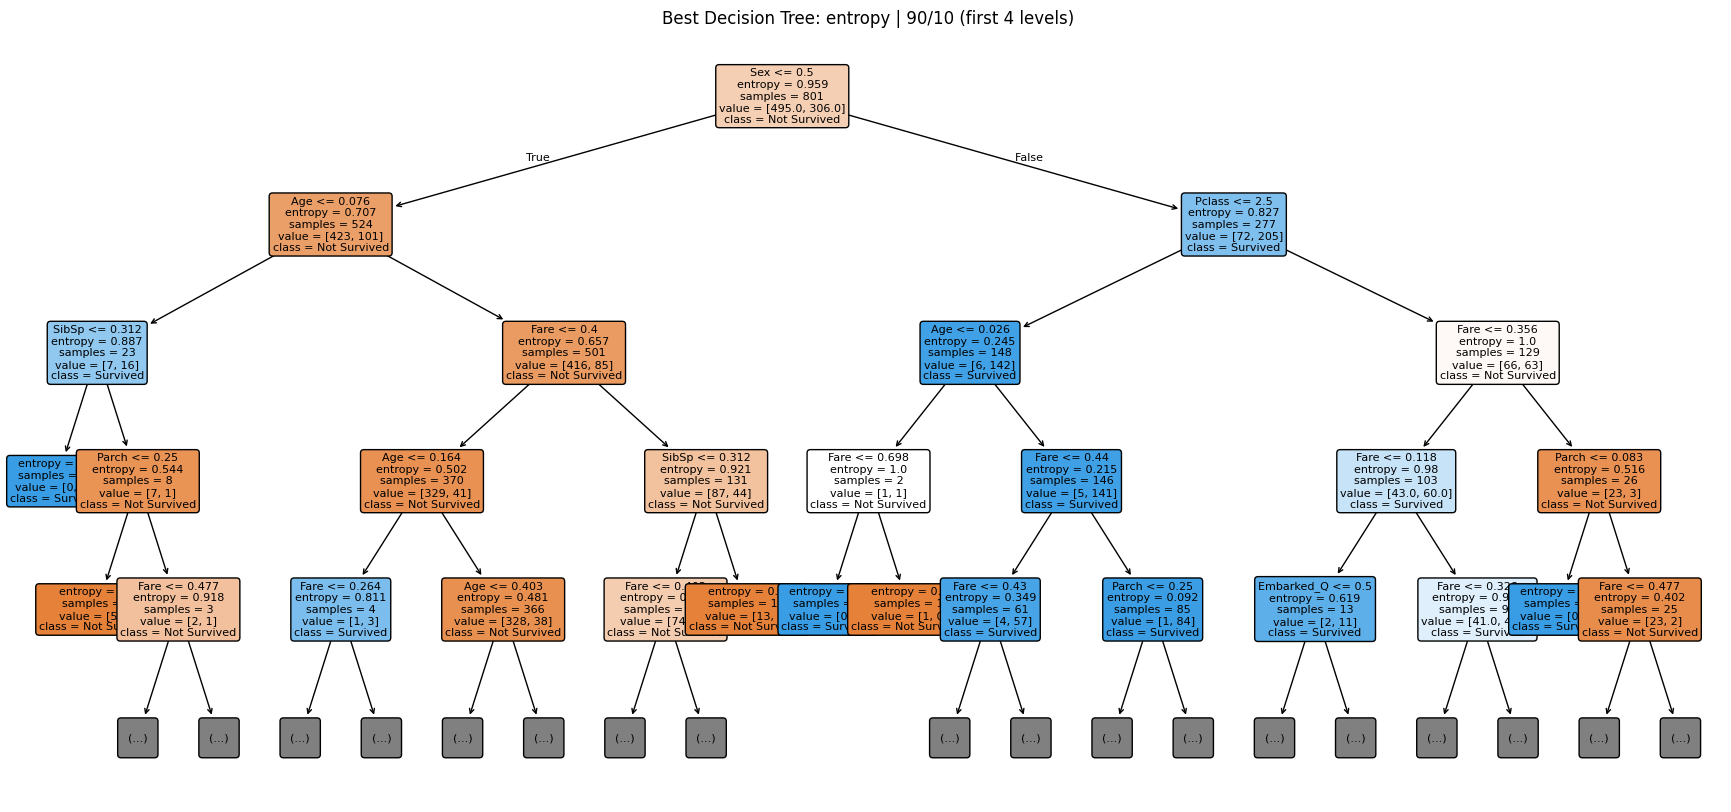

In [ ]:
sizes = {"90/10": 0.10, "80/20": 0.20, "70/30": 0.30}
best_crit, best_split = max(results, key=lambda k: (results[k], avg[k[0]]))
print("Best model:", best_crit, "|", best_split, "| Accuracy =", round(results[(best_crit, best_split)], 4))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=sizes[best_split], random_state=42)
best_model = DecisionTreeClassifier(criterion=best_crit, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(22, 10))
plot_tree(best_model, feature_names=X.columns, class_names=["Not Survived", "Survived"],
          filled=True, rounded=True, fontsize=8, max_depth=4)
plt.title(f"Best Decision Tree: {best_crit} | {best_split} (first 4 levels)")
plt.show()

### Discussion of the classification results

**Best measure for each partition:**
- **90/10:** Gini and Entropy are tied (accuracy = 0.80), and both produced the same confusion matrix.
- **80/20:** Entropy is better (0.7709 vs 0.7542 for Gini).
- **70/30:** Entropy is better (0.7687 vs 0.7463 for Gini).

**Best measure overall:** Entropy. It was better than or equal to Gini in every partition, and its average accuracy (0.780) is higher than Gini's (0.767).

**Best model:** Entropy with the 90/10 partition (accuracy = 0.80, confusion matrix [[43, 11], [7, 29]]). Accuracy decreases slightly when the test set gets larger, because less data is left for training. However, the 90/10 test set contains only 90 rows, so its accuracy is less stable than the other partitions.

**The final tree:** The root of the tree splits on `Sex`, which means it is the most informative attribute. Among females, the next split is on `Pclass`: first and second class females almost all survived. Among males, the next split is on `Age`: young boys survived more than adult men. This shows that sex, ticket class and age are the strongest predictors of survival. The Age and Fare thresholds look small (for example 0.076) because these features were normalized in the preprocessing step.